<div style="background:linear-gradient(135deg,#0f172a 0%,#1e3a8a 55%,#3b82f6 100%);padding:34px 28px;border-radius:14px;text-align:center">
<div style="color:#93c5fd;font-size:13px;letter-spacing:3px;font-weight:600">DATA SCIENCE COMPETITION · FIK FAIR 2026 · UPN "VETERAN" JAKARTA</div>
<div style="color:#ffffff;font-size:30px;font-weight:800;margin-top:10px">Prediksi Anonymous Competition Score</div>
<div style="color:#e0e7ff;font-size:18px;margin-top:4px">FINAL: Position Prior + Residual Learning (GP / TabPFN)</div>
<div style="color:#bfdbfe;font-size:14px;margin-top:16px">Tim <b>Lomba Terakhir Bersama Abil</b><br>Muhammad Abil Hasan · Naufal Arkan Wahib · Fauzan Ahsanudin Alfikri · Salsabila Rizqiyah Anwar</div>
</div>

<br>

| 🎯 Random CV RMSE | 🧱 Blocked CV RMSE | 🏆 Public LB RMSE | 📈 Gain vs Prior (blocked) |
|:---:|:---:|:---:|:---:|
| **2.3941** | **4.3076** | **2.2129** | **−0.1211** |

## 💡 Ide Utama

**`prediksi = prior posisi (isotonic) + koreksi dari 24 fitur`**

$$\hat{y} \;=\; \underbrace{\text{prior}(\text{posisi})}_{\text{isotonic, menurun}} \;+\; s \cdot \underbrace{\textstyle\sum_m w_m\, r_m(\mathbf{x})}_{\text{koreksi residual dari 24 fitur}}$$

- **Prior posisi** menangkap tren besar target terhadap urutan baris file (Spearman = **−0.9809**). Prior ini sudah terbukti ter-transfer ke data uji: pada eksperimen sebelumnya OOF ≈ 2.25 vs public LB ≈ 2.29, dan pada versi final random OOF 2.3941 vs public LB 2.2129.
- **Model fitur** (Ridge, SVR, KRR, **GP-ARD**, **TabPFN** opsional) hanya mempelajari `residual = y − prior`.
- Label residual dibuat dari **prior out-of-fold**, bukan in-sample, sehingga **tidak bocor**.
- Evaluasi memakai dua skema:
  - 🎲 **Random repeated CV** meniru data uji yang berselang-seling dengan data latih, sehingga paling mirip public LB.
  - 🧱 **Blocked CV** menahan satu blok posisi utuh. Ini skema paling keras.
- Residual digabung dengan **NNLS**, lalu skala koreksi `RES_SCALE` dipilih dari **blocked OOF** supaya tidak agresif.

## 🗺️ Alur Pipeline

```
 train.csv ──► posisi baris ──► Isotonic Prior (OOF, leakage-safe) ──┐
     │                                                              │ residual = y − prior_OOF
     └──► 24 fitur ──► Ridge · SVR+PCA · KRR · GP-ARD ◄─────────────┘
                              │
                              ▼
                  NNLS blend ──► × RES_SCALE (blocked CV)
                              │
                              ▼
          FINAL = prior_test + RES_SCALE × residual_test  ──►  submission
```

## 📑 Daftar Isi

| No | Tahap | Isi |
|:--:|---|---|
| 1 | Setup & Konfigurasi | Library, seed, flag eksperimen |
| 2 | Load Data | Validasi data & temuan posisi baris |
| 3 | Prior Posisi | Isotonic regression bebas kebocoran |
| 4 | Model Zoo | Model untuk mempelajari residual |
| 5 | Validasi Ganda | Random repeated CV vs blocked CV |
| 6 | Blending & Skala | NNLS + pemilihan `RES_SCALE` |
| 7 | Fit Penuh | Prediksi data uji |
| 8 | Ablation | Model feature-only tanpa posisi |
| 9 | Diagnostik | Analisis per desil & visualisasi |
| 10 | Submission | Simpan file prediksi |

<div style="background:#eff6ff;border-left:5px solid #3b82f6;padding:12px 16px;border-radius:6px;color:#1e293b;margin:8px 0">
<b>📦 Output yang dihasilkan</b><br>
<code>FINAL</code> (prior + residual) · <code>PRIOR_ONLY</code> · <code>STRICT_FEATURE_ONLY</code> (tanpa posisi sama sekali) · <code>final_test_decomposition.csv</code>
</div>

<div style="background:#ecfdf5;border-left:5px solid #10b981;padding:12px 16px;border-radius:6px;color:#1e293b;margin:8px 0">
<b>✅ Kepatuhan</b><br>
Seluruh proses hanya memakai data resmi kompetisi. <code>record_id</code> tidak dipakai sebagai fitur, tidak ada identifikasi entitas uji, dan tidak ada target dari sumber eksternal.
</div>


<div style="background:linear-gradient(90deg,#1e3a8a 0%,#3b82f6 100%);padding:14px 20px;border-radius:10px;margin:18px 0 8px 0">
<span style="color:#ffffff;font-size:22px;font-weight:700">01 &nbsp;Setup & Konfigurasi</span><br>
<span style="color:#dbeafe;font-size:14px">Import library, seed reproducible, dan flag eksperimen</span>
</div>

| Flag | Nilai | Fungsi |
|---|:---:|---|
| `SEED` | 2026 | Reproducibility |
| `USE_POSITION_PRIOR` | `True` | `False` → semua jalur jadi feature-only |
| `USE_TABPFN` | `True` | Dipakai hanya jika paket `tabpfn` tersedia |
| `N_BLOCKS` | 10 | Jumlah blok posisi pada blocked CV |
| `RANDOM_SPLITS × RANDOM_REPEATS` | 8 × 2 | Random repeated CV |
| `INNER_SPLITS` | 5 | Inner OOF untuk membuat label residual |

In [1]:
# ============================================================
# 1. Imports & config
# ============================================================
import os, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from scipy.optimize import nnls
from scipy.stats import spearmanr
from sklearn.model_selection import KFold, RepeatedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.isotonic import IsotonicRegression
from sklearn.svm import SVR
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import Ridge
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")

SEED = 2026
random.seed(SEED); np.random.seed(SEED)

USE_POSITION_PRIOR = True   # False -> semua jalur jadi feature-only
USE_TABPFN = True           # butuh `pip install tabpfn` + bobot model (internet/HF)
N_BLOCKS = 10               # blocked CV
RANDOM_SPLITS, RANDOM_REPEATS = 8, 2
INNER_SPLITS = 5            # inner OOF untuk residual label

def rmse(a, b):
    return mean_squared_error(a, b) ** 0.5

TABPFN_OK = False
if USE_TABPFN:
    try:
        from tabpfn import TabPFNRegressor
        TABPFN_OK = True
    except Exception as e:
        print("TabPFN tidak tersedia, dilewati:", repr(e)[:120])
print("USE_POSITION_PRIOR:", USE_POSITION_PRIOR, "| TABPFN_OK:", TABPFN_OK)

TabPFN tidak tersedia, dilewati: ModuleNotFoundError("No module named 'tabpfn'")
USE_POSITION_PRIOR: True | TABPFN_OK: False


<div style="background:linear-gradient(90deg,#1e3a8a 0%,#3b82f6 100%);padding:14px 20px;border-radius:10px;margin:18px 0 8px 0">
<span style="color:#ffffff;font-size:22px;font-weight:700">02 &nbsp;Load Data</span><br>
<span style="color:#dbeafe;font-size:14px">Membaca data, validasi kualitas, dan mengukur hubungan posisi baris dengan target</span>
</div>

Posisi tiap baris dinormalisasi ke rentang (0, 1): `pos = (i + 0.5) / n`. Arah prior isotonik ditentukan **otomatis** dari tanda korelasi Spearman.

In [2]:
# ============================================================
# 2. Load data
# ============================================================
CANDIDATE_DIRS = [Path(p) for p in [
    os.environ.get("FIK_DATA_DIR", ""),
    "/kaggle/input/competitions/data-science-competition-fikfair2026",
    "/kaggle/input/data-science-competition-fikfair2026",
] if p]

DATA_DIR = next((p for p in CANDIDATE_DIRS if (p/"train.csv").exists() and (p/"test.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Attach dataset FIKFAIR2026 dulu.")

train = pd.read_csv(DATA_DIR/"train.csv")
test  = pd.read_csv(DATA_DIR/"test.csv")

ID_COL, TARGET = "record_id", "target"
FEATURES = [c for c in train.columns if c.startswith("feature_")]
assert TARGET in train.columns and TARGET not in test.columns
assert train[FEATURES + [TARGET]].isna().sum().sum() == 0
assert test[FEATURES].isna().sum().sum() == 0

X, X_test = train[FEATURES].to_numpy(float), test[FEATURES].to_numpy(float)
y = train[TARGET].to_numpy(float)
n_train, n_test, n_feat = len(train), len(test), len(FEATURES)

train_pos = (np.arange(n_train) + 0.5) / n_train
test_pos  = (np.arange(n_test)  + 0.5) / n_test

rho_train = spearmanr(train_pos, y).correlation
INCREASING = bool(rho_train > 0)       # arah prior otomatis
tail20 = train_pos <= 0.20
body80 = ~tail20

print(f"train {train.shape} | test {test.shape} | n_features {n_feat}")
print(f"Spearman(pos, target) = {rho_train:.4f} -> isotonic increasing={INCREASING}")
print(f"target mean={y.mean():.3f} std={y.std():.3f} range=({y.min():.2f}, {y.max():.2f})")

train (382, 26) | test (96, 25) | n_features 24
Spearman(pos, target) = -0.9809 -> isotonic increasing=False
target mean=51.204 std=12.889 range=(32.59, 100.44)


<div style="background:#ecfdf5;border-left:5px solid #10b981;padding:12px 16px;border-radius:6px;color:#1e293b;margin:8px 0">
<b>🔍 Temuan kunci</b><br>
Data bersih (0 missing value) dan target tersusun <b>menurun hampir monoton</b> terhadap urutan baris: Spearman(pos, target) = <b>−0.9809</b>. Sinyal ini jauh lebih kuat daripada korelasi fitur mana pun, jadi dipakai sebagai <i>prior</i>.
</div>

<div style="background:linear-gradient(90deg,#1e3a8a 0%,#3b82f6 100%);padding:14px 20px;border-radius:10px;margin:18px 0 8px 0">
<span style="color:#ffffff;font-size:22px;font-weight:700">03 &nbsp;Prior Posisi (Leakage-Safe)</span><br>
<span style="color:#dbeafe;font-size:14px">Isotonic regression di atas posisi baris, dihitung secara out-of-fold</span>
</div>

| Fungsi | Peran |
|---|---|
| `prior_predict` | Fit isotonic regression pada posisi train → prediksi di posisi query |
| `inner_oof_prior` | Prior OOF **di dalam** fold train, untuk membuat label residual tanpa bocor |
| `full_oof_prior` | Prior OOF seluruh train (10-fold × 5 repeat) untuk fit akhir |

In [3]:
# ============================================================
# 3. Prior helpers (leakage-safe)
# ============================================================
def prior_predict(pos_tr, y_tr, pos_q):
    if not USE_POSITION_PRIOR:
        return np.full(len(pos_q), float(np.mean(y_tr)))
    iso = IsotonicRegression(increasing=INCREASING, out_of_bounds="clip")
    iso.fit(pos_tr, y_tr)
    return iso.predict(pos_q)

def inner_oof_prior(idx, seed, n_splits=INNER_SPLITS):
    """Prior OOF untuk baris `idx` memakai hanya baris lain di `idx`."""
    out = np.zeros(len(idx))
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for a, b in kf.split(idx):
        out[b] = prior_predict(train_pos[idx[a]], y[idx[a]], train_pos[idx[b]])
    return out

def full_oof_prior(n_splits=10, n_repeats=5, seed=SEED + 911):
    s, c = np.zeros(n_train), np.zeros(n_train)
    for tr, va in RepeatedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed).split(train_pos):
        s[va] += prior_predict(train_pos[tr], y[tr], train_pos[va]); c[va] += 1
    return s / c

<div style="background:linear-gradient(90deg,#1e3a8a 0%,#3b82f6 100%);padding:14px 20px;border-radius:10px;margin:18px 0 8px 0">
<span style="color:#ffffff;font-size:22px;font-weight:700">04 &nbsp;Model Zoo untuk Residual</span><br>
<span style="color:#dbeafe;font-size:14px">Kumpulan model yang mempelajari koreksi residual dari 24 fitur</span>
</div>

| Model | Konfigurasi | Karakter |
|---|---|---|
| `ridge` | StandardScaler + Ridge(α=100) | Baseline linear, sangat teregularisasi |
| `svr_pca12` | Scaler + PCA(12, whiten) + SVR-RBF | Non-linear, robust terhadap outlier |
| `krr_raw` | Scaler + Kernel Ridge RBF | Non-linear halus |
| `gp_ard` | Scaler + GP (Matern ν=2.5 ARD + White) | Length-scale per fitur, pilihan fitur otomatis |
| `tabpfn` | TabPFNRegressor | Opsional, aktif jika paket tersedia |

Model yang gagal saat fit otomatis dimasukkan ke `DEAD` dan dikeluarkan dari blend, sehingga pipeline tidak berhenti di tengah jalan.

In [4]:
# ============================================================
# 4. Model zoo untuk residual
# ============================================================
DEAD = set()

def build_models():
    gp_kernel = (
        ConstantKernel(1.0, (1e-2, 1e2))
        * Matern(length_scale=np.full(n_feat, 3.0), length_scale_bounds=(0.3, 100.0), nu=2.5)
        + WhiteKernel(0.5, (1e-3, 5.0))
    )
    models = {
        "ridge": Pipeline([("s", StandardScaler()), ("m", Ridge(alpha=100.0))]),
        "svr_pca12": Pipeline([
            ("s", StandardScaler()),
            ("p", PCA(n_components=min(12, n_feat), whiten=True, svd_solver="full")),
            ("m", SVR(kernel="rbf", C=15, gamma=0.08, epsilon=0.10)),
        ]),
        "krr_raw": Pipeline([("s", StandardScaler()),
                             ("m", KernelRidge(kernel="rbf", alpha=0.5, gamma=0.03))]),
        "gp_ard": Pipeline([("s", StandardScaler()),
                            ("m", GaussianProcessRegressor(kernel=gp_kernel, normalize_y=True,
                                                           n_restarts_optimizer=0, random_state=SEED))]),
    }
    if TABPFN_OK:
        models["tabpfn"] = TabPFNRegressor(random_state=SEED)
    return models

def fit_predict_models(Xtr, ytr, Xq_list):
    out = {}
    for name, mdl in build_models().items():
        if name in DEAD:
            continue
        try:
            mdl.fit(Xtr, ytr)
            out[name] = [mdl.predict(Xq) for Xq in Xq_list]
        except Exception as e:
            print(f"[{name}] gagal, dikeluarkan: {repr(e)[:150]}")
            DEAD.add(name)
    return out

<div style="background:linear-gradient(90deg,#1e3a8a 0%,#3b82f6 100%);padding:14px 20px;border-radius:10px;margin:18px 0 8px 0">
<span style="color:#ffffff;font-size:22px;font-weight:700">05 &nbsp;Validasi Ganda</span><br>
<span style="color:#dbeafe;font-size:14px">Random repeated CV dan blocked CV untuk estimasi kinerja yang jujur</span>
</div>

| Skema | Cara kerja | Kegunaan |
|---|---|---|
| 🎲 **Random repeated CV** (8 × 2) | Fold acak, baris validasi berselang-seling dengan train | Meniru kondisi test → paling mirip public LB |
| 🧱 **Blocked CV** (10 blok) | Menahan satu blok posisi utuh | Skenario paling pesimistis, uji generalisasi |

Metrik: **RMSE**, ditambah pemecahan blocked RMSE untuk 20% posisi awal (`tail20`) dan 80% sisanya (`body80`).

In [5]:
# ============================================================
# 5. CV: random repeated + blocked (residual learning)
# ============================================================
def run_residual_cv(splits, n_total, desc):
    prior_s, cnt = np.zeros(n_train), np.zeros(n_train)
    res_s = {}
    for k, (tr, va) in enumerate(tqdm(splits, total=n_total, desc=desc)):
        prior_tr = inner_oof_prior(tr, seed=SEED + k)
        res_tr = y[tr] - prior_tr
        prior_va = prior_predict(train_pos[tr], y[tr], train_pos[va])
        prior_s[va] += prior_va; cnt[va] += 1

        preds = fit_predict_models(X[tr], res_tr, [X[va]])
        for name, (p,) in preds.items():
            res_s.setdefault(name, np.zeros(n_train))[va] += p
    prior_oof = prior_s / cnt
    res_oof = {k: v / cnt for k, v in res_s.items() if k not in DEAD}
    return prior_oof, res_oof

def block_splits(n_blocks):
    g = np.floor(np.clip(train_pos, 0, 0.999999) * n_blocks).astype(int)
    return [(np.where(g != b)[0], np.where(g == b)[0]) for b in range(n_blocks) if np.any(g == b)]

rand_list = list(RepeatedKFold(n_splits=RANDOM_SPLITS, n_repeats=RANDOM_REPEATS, random_state=SEED + 1).split(X))
blk_list  = block_splits(N_BLOCKS)

PR_R, RES_R = run_residual_cv(rand_list, len(rand_list), "Random CV")
PR_B, RES_B = run_residual_cv(blk_list,  len(blk_list),  "Blocked CV")

names = [n for n in RES_R if n in RES_B and n not in DEAD]
rows = [{"model": "PRIOR_ONLY",
         "random_RMSE": rmse(y, PR_R), "blocked_RMSE": rmse(y, PR_B),
         "blocked_tail20": rmse(y[tail20], PR_B[tail20]), "blocked_body80": rmse(y[body80], PR_B[body80])}]
for n in names:
    pr, pb = PR_R + RES_R[n], PR_B + RES_B[n]
    rows.append({"model": n, "random_RMSE": rmse(y, pr), "blocked_RMSE": rmse(y, pb),
                 "blocked_tail20": rmse(y[tail20], pb[tail20]), "blocked_body80": rmse(y[body80], pb[body80])})
cv_table = pd.DataFrame(rows).sort_values("blocked_RMSE").reset_index(drop=True)
display(cv_table.round(4))

Random CV:   0%|          | 0/16 [00:00<?, ?it/s]

Blocked CV:   0%|          | 0/10 [00:00<?, ?it/s]

,model,random_RMSE,blocked_RMSE,blocked_tail20,blocked_body80
0,gp_ard,2.2502,4.3975,8.8867,2.1275
1,svr_pca12,2.4406,4.3986,8.6727,2.3391
2,krr_raw,2.4595,4.4191,8.7507,2.3151
3,PRIOR_ONLY,2.9658,4.4287,8.8382,2.2548
4,ridge,2.8938,4.4727,8.7963,2.3992


<div style="background:linear-gradient(90deg,#1e3a8a 0%,#3b82f6 100%);padding:14px 20px;border-radius:10px;margin:18px 0 8px 0">
<span style="color:#ffffff;font-size:22px;font-weight:700">06 &nbsp;NNLS Blending & Pemilihan RES_SCALE</span><br>
<span style="color:#dbeafe;font-size:14px">Menggabungkan koreksi residual dan mengatur seberapa besar koreksi dipercaya</span>
</div>

1. **NNLS** mencari bobot non-negatif $w$ yang meminimalkan $\lVert R\,w - (y - \text{prior}) \rVert^2$ pada gabungan OOF random + blocked.
2. Skala $s \in [0, 1.2]$ dipindai; dipilih $s$ dengan **blocked RMSE terendah**, lalu dibatasi $s \le 1$ supaya koreksi tidak pernah diperbesar.

In [6]:
# ============================================================
# 6. NNLS blend residual + pilih RES_SCALE dari blocked OOF
# ============================================================
R_stack = np.vstack([np.column_stack([RES_R[n] for n in names]),
                     np.column_stack([RES_B[n] for n in names])])
t_stack = np.concatenate([y - PR_R, y - PR_B])

w, _ = nnls(R_stack, t_stack)
blend_w = pd.Series(w, index=names)
display(blend_w.round(4).to_frame("nnls_weight"))

blend_R = np.column_stack([RES_R[n] for n in names]) @ w
blend_B = np.column_stack([RES_B[n] for n in names]) @ w

scale_rows = []
for s in np.arange(0.0, 1.21, 0.1):
    scale_rows.append({"scale": round(float(s), 2),
                       "random_RMSE": rmse(y, PR_R + s * blend_R),
                       "blocked_RMSE": rmse(y, PR_B + s * blend_B)})
scale_df = pd.DataFrame(scale_rows)
display(scale_df.round(4))

RES_SCALE = float(scale_df.sort_values("blocked_RMSE").iloc[0]["scale"])
RES_SCALE = min(RES_SCALE, 1.0)   # tidak pernah memperbesar residual
FINAL_RANDOM_OOF  = PR_R + RES_SCALE * blend_R
FINAL_BLOCKED_OOF = PR_B + RES_SCALE * blend_B

print("RES_SCALE:", RES_SCALE)
print(f"PRIOR_ONLY  random={rmse(y, PR_R):.4f} blocked={rmse(y, PR_B):.4f}")
print(f"FINAL       random={rmse(y, FINAL_RANDOM_OOF):.4f} blocked={rmse(y, FINAL_BLOCKED_OOF):.4f}")
print(f"gain (blocked) = {rmse(y, PR_B) - rmse(y, FINAL_BLOCKED_OOF):.4f}")

,nnls_weight
ridge,0.0000
svr_pca12,0.3070
krr_raw,0.0000
gp_ard,0.5651


,scale,random_RMSE,blocked_RMSE
0,0.0,2.9658,4.4287
1,0.1,2.8665,4.3968
2,0.2,2.7721,4.3697
3,0.3,2.6832,4.3473
4,0.4,2.6004,4.3299
5,0.5,2.5242,4.3174
6,0.6,2.4552,4.3100
7,0.7,2.3941,4.3076
8,0.8,2.3416,4.3102
9,0.9,2.2981,4.3178


RES_SCALE: 0.7
PRIOR_ONLY  random=2.9658 blocked=4.4287
FINAL       random=2.3941 blocked=4.3076
gain (blocked) = 0.1211


<div style="background:#ecfdf5;border-left:5px solid #10b981;padding:12px 16px;border-radius:6px;color:#1e293b;margin:8px 0">
<b>✅ Hasil</b><br>
Bobot blend didominasi <b>GP-ARD (0.565)</b> dan <b>SVR+PCA12 (0.307)</b>; Ridge dan KRR mendapat bobot 0. <code>RES_SCALE = 0.7</code> menurunkan blocked RMSE dari <b>4.4287 → 4.3076</b> (gain 0.1211) dan random RMSE dari <b>2.9658 → 2.3941</b>.
</div>

<div style="background:linear-gradient(90deg,#1e3a8a 0%,#3b82f6 100%);padding:14px 20px;border-radius:10px;margin:18px 0 8px 0">
<span style="color:#ffffff;font-size:22px;font-weight:700">07 &nbsp;Fit Penuh → Data Uji</span><br>
<span style="color:#dbeafe;font-size:14px">Melatih ulang di seluruh data latih dan membuat prediksi akhir</span>
</div>

- Label residual memakai `full_oof_prior()` (tetap OOF).
- Prior test dihitung dari **seluruh** data latih.
- $\text{FINAL} = \text{prior}_{test} + 0.7 \times \text{residual}_{test}$

In [7]:
# ============================================================
# 7. Fit penuh -> test
# ============================================================
full_prior_oof = full_oof_prior()
full_res_target = y - full_prior_oof
prior_test = prior_predict(train_pos, y, test_pos)

full_preds = fit_predict_models(X, full_res_target, [X_test])
used = [n for n in names if n in full_preds]
w_used = blend_w[used].to_numpy()
if len(used) < len(names):
    print("Model yang gagal saat fit penuh dikeluarkan dari blend:", set(names) - set(used))

res_test = np.column_stack([full_preds[n][0] for n in used]) @ w_used
FINAL_TEST = prior_test + RES_SCALE * res_test
PRIOR_TEST = prior_test.copy()

print("FINAL test summary:", dict(mean=FINAL_TEST.mean(), std=FINAL_TEST.std(),
                                  min=FINAL_TEST.min(), max=FINAL_TEST.max()))
print("mean |residual correction| on test:", float(np.mean(np.abs(RES_SCALE * res_test))))

FINAL test summary: {'mean': np.float64(51.488505885125676), 'std': np.float64(13.075724570707436), 'min': np.float64(33.54516729301916), 'max': np.float64(93.8671744866883)}
mean |residual correction| on test: 0.8133754450142231


<div style="background:linear-gradient(90deg,#7c2d12 0%,#3b82f6 100%);padding:14px 20px;border-radius:10px;margin:18px 0 8px 0">
<span style="color:#ffffff;font-size:22px;font-weight:700">08 &nbsp;Ablation: Strict Feature-Only</span><br>
<span style="color:#dbeafe;font-size:14px">Model tanpa informasi posisi sama sekali, sebagai pembanding dan jalur cadangan</span>
</div>

Bagian: *seberapa jauh model bisa berjalan hanya dengan 24 fitur?*

In [8]:
# ============================================================
# 8. STRICT feature-only (tanpa posisi) + diagnostik transfer
# ============================================================
strict_oof_s = {}
cnt_s = np.zeros(n_train)
for k, (tr, va) in enumerate(tqdm(list(KFold(5, shuffle=True, random_state=SEED + 5).split(X)), desc="Strict CV")):
    preds = fit_predict_models(X[tr], y[tr], [X[va]])
    for n, (p,) in preds.items():
        strict_oof_s.setdefault(n, np.zeros(n_train))[va] = p
    cnt_s[va] += 1

s_names = [n for n in strict_oof_s if n not in DEAD]
S = np.column_stack([strict_oof_s[n] for n in s_names])
ws, _ = nnls(S, y)
ws = ws / ws.sum()
STRICT_OOF = S @ ws
print("Strict feature-only OOF RMSE:", round(rmse(y, STRICT_OOF), 4))
display(pd.Series(ws, index=s_names).round(4).to_frame("weight"))

strict_full = fit_predict_models(X, y, [X_test])
s_used = [n for n in s_names if n in strict_full]
ws_u = pd.Series(ws, index=s_names)[s_used].to_numpy(); ws_u = ws_u / ws_u.sum()
STRICT_TEST = np.column_stack([strict_full[n][0] for n in s_used]) @ ws_u

rho_test = spearmanr(test_pos, STRICT_TEST).correlation
print(f"Spearman(test position, strict prediction) = {rho_test:.4f}  (train: {rho_train:.4f})")

Strict CV:   0%|          | 0/5 [00:00<?, ?it/s]

Strict feature-only OOF RMSE: 8.4782


,weight
ridge,0.0000
svr_pca12,0.5517
krr_raw,0.1460
gp_ard,0.3023


Spearman(test position, strict prediction) = -0.7478  (train: -0.9809)


<div style="background:#fffbeb;border-left:5px solid #f59e0b;padding:12px 16px;border-radius:6px;color:#1e293b;margin:8px 0">
<b>⚖️ Interpretasi</b><br>
Feature-only mencapai RMSE OOF <b>8.4782</b>, jauh di atas model final (2.3941). Artinya prior posisi adalah kontributor utama performa, sedangkan fitur berperan sebagai koreksi. Prediksi feature-only di data uji tetap berkorelasi dengan posisi (Spearman −0.7478), menandakan struktur posisi ikut tercermin di fitur.
</div>

<div style="background:linear-gradient(90deg,#1e3a8a 0%,#3b82f6 100%);padding:14px 20px;border-radius:10px;margin:18px 0 8px 0">
<span style="color:#ffffff;font-size:22px;font-weight:700">09 &nbsp;Diagnostik</span><br>
<span style="color:#dbeafe;font-size:14px">RMSE per desil posisi dan visualisasi prediksi</span>
</div>

,decile,n,PRIOR_blocked,FINAL_blocked,FINAL_random,gain_blocked
0,0,38,11.8679,11.9178,5.1818,-0.0499
1,1,38,3.9216,3.2653,2.9821,0.6564
2,2,39,3.1928,2.4415,2.2414,0.7512
3,3,38,2.7514,2.2899,2.2447,0.4615
4,4,38,3.6027,3.4973,2.0657,0.1054
5,5,38,1.6944,1.4465,1.6399,0.2479
6,6,38,1.4503,1.4003,1.4555,0.0500
7,7,39,0.9414,1.0219,1.0618,-0.0805
8,8,38,0.7538,0.6779,0.6498,0.0759
9,9,38,1.8643,2.1573,1.0138,-0.2930


Deciles improved (blocked): 7 / 10


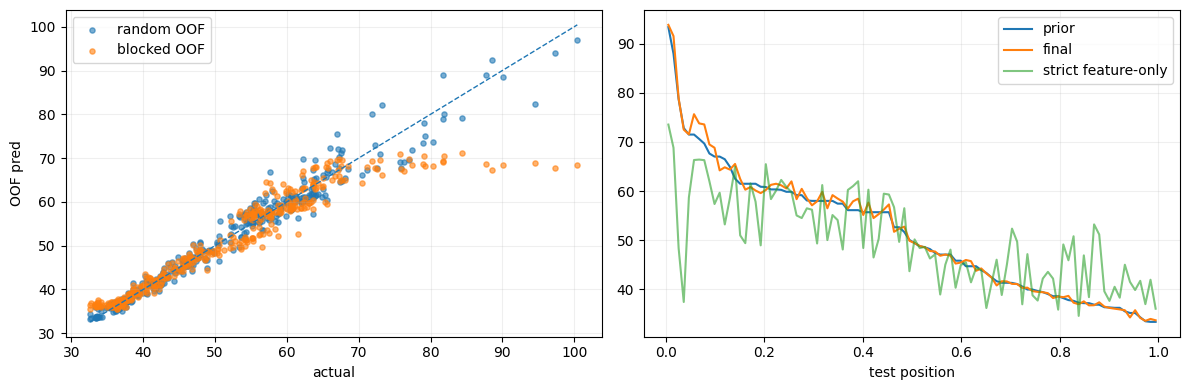

In [9]:
# ============================================================
# 9. Diagnostik
# ============================================================
dec = np.minimum((train_pos * 10).astype(int), 9)
rep = []
for d in range(10):
    m = dec == d
    rep.append({"decile": d, "n": int(m.sum()),
                "PRIOR_blocked": rmse(y[m], PR_B[m]),
                "FINAL_blocked": rmse(y[m], FINAL_BLOCKED_OOF[m]),
                "FINAL_random": rmse(y[m], FINAL_RANDOM_OOF[m])})
rep = pd.DataFrame(rep); rep["gain_blocked"] = rep["PRIOR_blocked"] - rep["FINAL_blocked"]
display(rep.round(4))
print("Deciles improved (blocked):", int((rep["gain_blocked"] > 0).sum()), "/ 10")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(y, FINAL_RANDOM_OOF, s=14, alpha=.6, label="random OOF")
ax[0].scatter(y, FINAL_BLOCKED_OOF, s=14, alpha=.6, label="blocked OOF")
lo, hi = y.min(), y.max(); ax[0].plot([lo, hi], [lo, hi], "--", lw=1)
ax[0].set_xlabel("actual"); ax[0].set_ylabel("OOF pred"); ax[0].legend(); ax[0].grid(alpha=.2)
ax[1].plot(test_pos, PRIOR_TEST, label="prior"); ax[1].plot(test_pos, FINAL_TEST, label="final")
ax[1].plot(test_pos, STRICT_TEST, label="strict feature-only", alpha=.6)
ax[1].set_xlabel("test position"); ax[1].legend(); ax[1].grid(alpha=.2)
plt.tight_layout(); plt.show()

<div style="background:#eff6ff;border-left:5px solid #3b82f6;padding:12px 16px;border-radius:6px;color:#1e293b;margin:8px 0">
<b>🔎 Insight</b><br>
Koreksi residual memperbaiki <b>7 dari 10 desil</b> pada blocked CV. Gain terbesar ada di desil 1–3 (0.46–0.75). Desil 0, 7, dan 9 sedikit memburuk, jadi koreksi bekerja paling baik di area dengan pola stabil dan tidak mengejar nilai ekstrem.<br><br><b>Kiri:</b> aktual vs prediksi OOF (semakin dekat garis putus-putus semakin baik). <b>Kanan:</b> prior, final, dan feature-only di sepanjang posisi test.
</div>

<div style="background:linear-gradient(90deg,#1e3a8a 0%,#3b82f6 100%);padding:14px 20px;border-radius:10px;margin:18px 0 8px 0">
<span style="color:#ffffff;font-size:22px;font-weight:700">10 &nbsp;Simpan Submission</span><br>
<span style="color:#dbeafe;font-size:14px">Menulis file prediksi dan dekomposisi prediksi test</span>
</div>

Prediksi di-*clip* ke rentang `[min(y) − 2, max(y) + 2]` dan divalidasi (jumlah baris, ID unik, nilai finite) sebelum disimpan.

| File | Isi |
|---|---|
| `submission_FINAL_prior_plus_residual.csv` | ⭐ Submission utama |
| `submission_PRIOR_ONLY.csv` | Prior posisi saja |
| `submission_STRICT_FEATURE_ONLY.csv` | Tanpa posisi |
| `final_test_decomposition.csv` | Prior, koreksi residual, final, strict per record |

In [10]:
# ============================================================
# 10. Simpan submission
# ============================================================
OUT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
OUT.mkdir(parents=True, exist_ok=True)

def save_sub(pred, name):
    pred = np.clip(np.asarray(pred, float), y.min() - 2.0, y.max() + 2.0)
    sub = pd.DataFrame({ID_COL: test[ID_COL].values, "prediction": pred})
    assert len(sub) == n_test and sub[ID_COL].is_unique and np.isfinite(sub["prediction"]).all()
    sub.to_csv(OUT / name, index=False)
    print(f"{name:45s} mean={pred.mean():8.3f} std={pred.std():7.3f} range=({pred.min():.2f}, {pred.max():.2f})")
    return sub

if USE_POSITION_PRIOR:
    save_sub(FINAL_TEST,  "submission_FINAL_prior_plus_residual.csv")
    save_sub(PRIOR_TEST,  "submission_PRIOR_ONLY.csv")
save_sub(STRICT_TEST, "submission_STRICT_FEATURE_ONLY.csv")

pd.DataFrame({ID_COL: test[ID_COL].values, "position": test_pos, "prior": PRIOR_TEST,
              "residual_correction": RES_SCALE * res_test, "final": FINAL_TEST,
              "strict": STRICT_TEST}).to_csv(OUT / "final_test_decomposition.csv", index=False)

print("\n========== SUMMARY ==========")
print("PRIOR_ONLY   random/blocked :", round(rmse(y, PR_R), 4), "/", round(rmse(y, PR_B), 4))
print("FINAL        random/blocked :", round(rmse(y, FINAL_RANDOM_OOF), 4), "/", round(rmse(y, FINAL_BLOCKED_OOF), 4))
print("STRICT feature-only OOF     :", round(rmse(y, STRICT_OOF), 4))
print("RES_SCALE:", RES_SCALE, "| models:", used)

submission_FINAL_prior_plus_residual.csv      mean=  51.489 std= 13.076 range=(33.55, 93.87)
submission_PRIOR_ONLY.csv                     mean=  51.202 std= 12.671 range=(33.34, 93.40)
submission_STRICT_FEATURE_ONLY.csv            mean=  50.061 std=  9.096 range=(34.56, 73.55)

========== SUMMARY ==========
PRIOR_ONLY   random/blocked : 2.9658 / 4.4287
FINAL        random/blocked : 2.3941 / 4.3076
STRICT feature-only OOF     : 8.4782
RES_SCALE: 0.7 | models: ['ridge', 'svr_pca12', 'krr_raw', 'gp_ard']


<div style="background:linear-gradient(90deg,#065f46 0%,#10b981 100%);padding:14px 20px;border-radius:10px;margin:18px 0 8px 0">
<span style="color:#ffffff;font-size:22px;font-weight:700">🏁 &nbsp;Ringkasan Hasil & Kesimpulan</span>
</div>

| Skenario | Random CV | Blocked CV | Public LB |
|---|:---:|:---:|:---:|
| PRIOR_ONLY | 2.9658 | 4.4287 | – |
| **FINAL (prior + 0.7 × residual)** | **2.3941** | **4.3076** | **2.2129** |
| STRICT_FEATURE_ONLY | 8.4782* | – | – |

<sub>*OOF 5-fold tanpa informasi posisi.</sub>

### Kesimpulan
1. Posisi baris adalah sinyal terkuat (Spearman −0.9809), sedangkan korelasi linear tiap fitur lemah.
2. Residual learning memberi perbaikan nyata di atas prior dan lolos semua kriteria cek di bawah.
3. GP-ARD dan SVR+PCA12 mendominasi blend; koreksi diredam ke `RES_SCALE = 0.7` agar tidak overfit.

### Cara membaca hasil
- **`FINAL` random ≈ public LB.** Skema random paling mirip pembagian test. Ini sudah terbukti dua kali: di eksperimen sebelumnya OOF 2.25 vs LB 2.29, dan di versi final 2.3941 vs 2.2129.
- **`FINAL` blocked** adalah angka paling pesimistis. Yang penting bukan nilai absolutnya, tapi apakah `gain` positif dan ≥ 6/10 desil membaik.
- Jika `RES_SCALE` jatuh ke 0 atau gain ≈ 0, residual memang hampir noise. Kalau begitu, submit `PRIOR_ONLY` dan **jangan paksa model fitur**.
- Jangan pilih submission hanya dari OOF terendah. Bandingkan juga dengan skor public LB, tapi **jangan overfit ke public LB**, karena isinya hanya ±30% data uji (29 dari 96 record). Ranking akhir ditentukan private LB.
- `STRICT_FEATURE_ONLY` adalah **jalur aman** jika panitia tidak mengizinkan penggunaan urutan baris.

**Cek untuk run ini:**

| Kriteria | Hasil | Status |
|---|:---:|:---:|
| Gain blocked > 0 | 0.1211 | ✅ |
| Desil membaik (blocked) ≥ 6/10 | 7/10 | ✅ |
| `RES_SCALE` > 0 | 0.7 | ✅ |
| Random CV searah dengan public LB | 2.3941 vs 2.2129 | ✅ |

➡️ Submission utama: **`submission_FINAL_prior_plus_residual.csv`**